# ACA 1 Preparación y exploración de datos sobre intención de abandono
**Autor del proyecto:** Jhonathan Holguin Rivera. Especialización en Analítica de Datos, CUN.

Análisis secundario de la encuesta de la Universidad Nacional de Colombia, sede de La Paz (2025).
Este cuaderno desarrolla el objetivo específico 1 mediante revisión de calidad, ETL y EDA multivariado.
Los tres resultados de interés son las respuestas ordinales sobre intención de abandono por motivos
personales, socioeconómicos y académicos. No se construye una etiqueta de deserción efectiva.

**Fuente:** Correa, C. (2026), Mendeley Data, versión 2, https://doi.org/10.17632/kxgrpy8sfp.2.
Licencia de datos CC BY 4.0. Código propio MIT. La publicación de la fuente no implica aval de la universidad.

**Ejecución:** abrir en Google Colab o Jupyter y ejecutar todas las celdas en orden. El cuaderno
busca el ZIP original en `data/raw/`. En Colab permite cargarlo desde el computador; fuera de Colab
se puede descargar desde la fuente y colocarlo allí. El archivo original no se incluye en el paquete
destinado al repositorio público. No se debe subir ese original a GitHub.

No se han ejecutado aún modelos predictivos ni pruebas confirmatorias de los objetivos siguientes.

**Revisión de escalas:** la documentación general y el README indican dirección creciente, pero
López-López, Bru-Cordero y Correa-Álvarez (2026), Cogent Education, DOI
10.1080/2331186X.2026.2722463, sección Variables, precisan que las tres respuestas de intención
originales tienen dirección inversa: valores bajos expresan mayor consideración del abandono.
Se adopta su regla explícita `6 − x`, se conservan las tres respuestas originales y se documenta
la discrepancia. No se dispone del formulario original ni de los textos exactos de las cinco alternativas.


In [12]:
from pathlib import Path
from zipfile import ZipFile
from io import BytesIO
import json, hashlib, re, unicodedata, sys, platform, importlib.metadata
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    def display(value):
        print(value.to_string(index=False) if hasattr(value,'to_string') else value)

SEED = 20261024
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
for folder in ['data/raw','data/processed','results/tables','results/figures','models']:
    (ROOT/folder).mkdir(parents=True, exist_ok=True)
TABLES = ROOT/'results/tables'
FIGURES = ROOT/'results/figures'
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Liberation Serif','DejaVu Serif'],
                     'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'svg.fonttype':'none'})

def save_table(frame, name):
    frame.to_csv(TABLES/f'{name}.csv', index=False, encoding='utf-8-sig')
    return frame

def save_figure(fig, name):
    fig.savefig(FIGURES/f'{name}.png', dpi=300, bbox_inches='tight')
    fig.savefig(FIGURES/f'{name}.svg', bbox_inches='tight')
    plt.show()
    plt.close(fig)

environment = {'python':platform.python_version(),'platform':platform.platform(),'seed':SEED,
               'packages':{p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','matplotlib','openpyxl']}}
(ROOT/'results/environment.json').write_text(json.dumps(environment,indent=2),encoding='utf-8')
print('Entorno registrado. Semilla:', SEED)


Entorno registrado. Semilla: 20261024


## 1 Adquisición y comprensión de la fuente
Se conserva una copia privada del ZIP original. La fecha 24 de octubre de 2026 corresponde a
la recepción del archivo en esta sesión; la hora exacta de descarga del usuario no se conoce.
El SHA-256 permite comprobar que futuras ejecuciones emplean los mismos bytes.
La ficha distingue las columnas reales del archivo de las variables declaradas por la fuente.


In [13]:
source_zip = ROOT/'data/raw/student_retention_dataset_lapaz_2025.zip'
if not source_zip.exists():
    try:
        from google.colab import files
    except ImportError:
        raise FileNotFoundError('Descargue el ZIP de https://data.mendeley.com/datasets/kxgrpy8sfp/2 y colóquelo en data/raw/.')
    print('Seleccione student_retention_dataset_lapaz_2025.zip o el ZIP que lo contiene.')
    uploads = files.upload()
    candidates = [v for k,v in uploads.items() if k.lower().endswith('.zip')]
    if len(candidates) != 1:
        raise ValueError('Cargue exactamente un ZIP de la fuente.')
    payload = candidates[0]
    with ZipFile(BytesIO(payload)) as z:
        nested = [n for n in z.namelist() if n.endswith('.zip')]
        if nested:
            if len(nested) != 1: raise ValueError('Paquete ambiguo.')
            payload = z.read(nested[0])
    source_zip.write_bytes(payload)

payload = source_zip.read_bytes()
source_sha256 = hashlib.sha256(payload).hexdigest()
with ZipFile(BytesIO(payload)) as z:
    xlsx_names = [n for n in z.namelist() if n.lower().endswith('.xlsx')]
    if len(xlsx_names) != 1: raise ValueError('Se esperaba un único libro de Excel.')
    raw = pd.read_excel(BytesIO(z.read(xlsx_names[0])),sheet_name='Data',dtype=object)
assert raw.shape == (333,34), 'La fuente cambió: revise la ficha y las decisiones antes de continuar.'
headers_original = raw.columns.tolist()
names = ['marca_temporal','genero','edad','estado_civil','municipio_origen','programa','primera_generacion',
         'transporte','discapacidad','apoyo_ambiente_familiar','importancia_apoyo_familiar','intencion_personal',
         'desafios','factores_personales_continuar','factores_personales_abandonar','estrato','vivienda',
         'ayuda_financiera','intencion_socioeconomica','factores_socioeconomicos_continuar',
         'factores_socioeconomicos_abandonar','colegio_origen','naturaleza_colegio','jornada_colegio',
         'satisfaccion_programa','satisfaccion_induccion','satisfaccion_docencia','dedicacion_estudio',
         'oportunidades_laborales','intencion_academica','factores_academicos_continuar',
         'factores_academicos_abandonar','pesos_factores_texto','busqueda_ayuda']
source = raw.copy()
source.columns = names
TARGETS = ['intencion_personal','intencion_socioeconomica','intencion_academica']
TARGET_LABELS = dict(zip(TARGETS,['Personal','Socioeconómica','Académica']))
ORDINAL = ['apoyo_ambiente_familiar','importancia_apoyo_familiar','intencion_personal','estrato',
           'intencion_socioeconomica','satisfaccion_programa','satisfaccion_induccion','satisfaccion_docencia',
           'dedicacion_estudio','oportunidades_laborales','intencion_academica']
PREDICTORS = [c for c in ORDINAL if c not in TARGETS]
ficha = pd.DataFrame([
    ('Título','Survey Dataset on Student Retention at the National University of Colombia, La Paz Campus (2025)'),
    ('Autor de los datos','Cristian Correa'),('Versión','2'),('Publicación','2026-03-27'),
    ('Fuente','https://data.mendeley.com/datasets/kxgrpy8sfp/2'),('DOI','10.17632/kxgrpy8sfp.2'),
    ('Licencia','CC BY 4.0; https://creativecommons.org/licenses/by/4.0/'),
    ('Adquisición','Descarga manual aportada por la usuaria'),('Recepción','2026-10-24, America/Bogota'),
    ('Fecha exacta de descarga','No confirmada; no confundir con fecha de recepción'),
    ('Periodo declarado por la publicación','Agosto a diciembre de 2025; no inferido de la marca temporal'),
    ('Unidad de análisis','Respuesta de un estudiante encuestado'),('Registros observados',len(raw)),
    ('Columnas observadas',raw.shape[1]),('Variables declaradas en la documentación',33),
    ('Resultados de interés','intencion_personal, intencion_socioeconomica, intencion_academica; ordinales 1–5'),
    ('Limitación','Sin seguimiento de matrícula ni resultado de deserción efectiva'),('SHA256 del ZIP',source_sha256)
],columns=['campo','valor'])
save_table(ficha,'ficha_dataset')
print(f'Archivo original: {len(raw)} registros y {raw.shape[1]} columnas.')
print('SHA-256:',source_sha256)


Archivo original: 333 registros y 34 columnas.
SHA-256: 72d788f9e3a20b4923e9be5ca2edc1907ee006e7d0a7cac0b0cd4c551e766d5f


## 2 ETL y protección de los registros
Se eliminan de la base analítica la marca temporal, el municipio, el colegio de procedencia y la
variable de discapacidad, no necesarios para esta caracterización y que añaden detalle personal.
La edad se presenta por intervalos; se conserva internamente su orden para la mediana, sin atribuir
un valor exacto a `29+`. Las categorías de texto poco frecuentes se agrupan en la copia procesada.
Estas medidas minimizan el detalle, pero no constituyen una certificación formal de anonimización.
No se ajustan imputadores, escaladores ni codificadores para entrenar modelos.


In [14]:
def norm_text(value):
    if pd.isna(value): return pd.NA
    return re.sub(r'\s+',' ',unicodedata.normalize('NFKC',str(value))).strip()

clean = source.copy()
normalizations = []
for col in names:
    if col == 'marca_temporal': continue
    before = clean[col].astype(str)
    clean[col] = clean[col].map(norm_text)
    changed = int((before != clean[col].astype(str)).sum())
    normalizations.append({'variable':col,'normalizaciones_espacios_unicode':changed})
for col in ORDINAL:
    clean[col] = pd.to_numeric(clean[col],errors='coerce')
    limit = 6 if col=='estrato' else 5
    if not (clean[col].dropna().between(1,limit) & (clean[col].dropna()%1==0)).all():
        raise ValueError(f'Fuera de rango: {col}')
    clean[col] = clean[col].astype('Int64')
raw_intentions = clean[TARGETS].copy()
# Regla explícita de los autores en Cogent Education (2026), sección Variables:
# los valores bajos originales indican mayor consideración de abandono.
# Se conserva el original para verificar que no se invierta dos veces.
for col in TARGETS:
    clean[col] = 6 - raw_intentions[col]
scale_audit = []
for col in TARGETS:
    for original in range(1,6):
        scale_audit.append({'variable':col,'puntuacion_original':original,'puntuacion_analitica':6-original,
                            'n':int(raw_intentions[col].eq(original).sum()),
                            'direccion_original':'Menor puntuación = mayor consideración de abandono',
                            'direccion_analitica':'Mayor puntuación = mayor consideración de abandono',
                            'regla':'6 - x','fuente_especifica':'https://doi.org/10.1080/2331186X.2026.2722463',
                            'limite':'Dirección documentada por autores; sin formulario con anclajes verbales exactos'})
save_table(pd.DataFrame(scale_audit),'auditoria_recodificacion_escalas')
missing_raw = int(raw.isna().sum().sum())
duplicate_full = int(raw.duplicated().sum())
duplicate_no_time = int(source.drop(columns='marca_temporal').duplicated().sum())

# No se interpreta 29+ como edad exacta. Se asigna directamente al intervalo abierto 26+.
def age_group(x):
    if str(x) == '29+': return '26 o más'
    n = int(float(x))
    if 17 <= n <= 19: return '17–19'
    if 20 <= n <= 22: return '20–22'
    if 23 <= n <= 25: return '23–25'
    if n >=26: return '26 o más'
    raise ValueError('Edad no prevista; revisar antes de agrupar.')
clean['grupo_edad'] = clean['edad'].map(age_group)

# Extracción numérica: se exige una terna; se verifica por separado su orden personal/económico/académico.
def parse_weights(text):
    values = re.findall(r'-?\d+(?:[.,]\d+)?', str(text))
    if len(values) != 3: return [np.nan]*3
    return [float(v.replace(',','.')) for v in values]
weights = pd.DataFrame(clean['pesos_factores_texto'].map(parse_weights).tolist(),
                       columns=['peso_personal','peso_socioeconomico','peso_academico'],index=clean.index)
valid_range = weights.notna().all(axis=1) & weights.ge(0).all(axis=1) & weights.le(100).all(axis=1)
weight_sum = weights.sum(axis=1,min_count=3)
valid_sum = valid_range & np.isclose(weight_sum,100,atol=1e-8)
zero_sum = valid_range & np.isclose(weight_sum,0,atol=1e-8)
audit_weights = pd.DataFrame({'estado':np.select([~valid_range,valid_sum,zero_sum],
                                              ['No interpretable o fuera de rango','Suma 100','Suma cero'],
                                              default='Otra suma distinta de 100')})
weights_quality = audit_weights.value_counts().rename('n').reset_index()
weights_quality['porcentaje'] = weights_quality['n']/len(raw)*100
save_table(weights_quality,'calidad_pesos')

EXCLUDE = ['marca_temporal','municipio_origen','colegio_origen','discapacidad','edad','pesos_factores_texto']
processed = clean.drop(columns=EXCLUDE).copy()
for col in TARGETS:
    processed[col+'_original'] = raw_intentions[col]
for col in ['desafios','factores_personales_continuar','factores_personales_abandonar',
            'factores_socioeconomicos_continuar','factores_socioeconomicos_abandonar',
            'factores_academicos_continuar','factores_academicos_abandonar']:
    processed[col] = processed[col].replace({'ninguna':'Ninguno','Ninguna':'Ninguno','ninguno':'Ninguno'})
    freq = processed[col].value_counts()
    processed[col] = processed[col].where(processed[col].map(freq)>=5,'Otras respuestas')
processed['estado_civil'] = processed['estado_civil'].replace({'Casado':'Casado o unión libre','Unión libre':'Casado o unión libre'})
processed['estrato_grupo'] = clean['estrato'].map(lambda x:str(x) if x<=2 else '3–6')
processed = processed.drop(columns='estrato')
processed['busqueda_ayuda'] = np.where(clean['busqueda_ayuda'].eq('No buscaría ayuda'),'No buscaría ayuda','Buscaría ayuda')
processed['pesos_suman_100'] = valid_sum.to_numpy()
# Los pesos individuales se conservan solo en memoria: en resultados se publican resúmenes.
processed.to_csv(ROOT/'data/processed/encuesta_preparada.csv',index=False,encoding='utf-8-sig')
save_table(pd.DataFrame(normalizations),'normalizacion_texto')
quality = pd.DataFrame([
 ['Registros',len(raw),len(processed),'No se eliminan participantes'],
 ['Columnas',raw.shape[1],processed.shape[1],'Exclusiones, agrupaciones y bandera de integridad documentadas'],
 ['Celdas vacías',missing_raw,int(processed.isna().sum().sum()),'No se imputa'],
 ['Filas duplicadas completas',duplicate_full,int(processed.duplicated().sum()),'La agrupación puede hacer coincidir perfiles distintos; no borrar'],
 ['Duplicados originales sin marca temporal',duplicate_no_time,np.nan,'Comprobación sobre la fuente'],
 ['Respuestas con pesos que suman 100',int(valid_sum.sum()),int(processed.pesos_suman_100.sum()),'Solo aptas para análisis composicional estricto'],
 ['Respuestas con pesos que no suman 100',int((~valid_sum).sum()),int((~processed.pesos_suman_100).sum()),'Se conserva el resto de las respuestas']
],columns=['indicador','antes','despues','tratamiento'])
save_table(quality,'etl_antes_despues')
display(quality)


,indicador,antes,despues,tratamiento
0,Registros,333,333.0,No se eliminan participantes
1,Columnas,34,33.0,"Exclusiones, agrupaciones y bandera de integri..."
2,Celdas vacías,0,0.0,No se imputa
3,Filas duplicadas completas,0,0.0,La agrupación puede hacer coincidir perfiles d...
4,Duplicados originales sin marca temporal,0,NaN,Comprobación sobre la fuente
5,Respuestas con pesos que suman 100,288,288.0,Solo aptas para análisis composicional estricto
6,Respuestas con pesos que no suman 100,45,45.0,Se conserva el resto de las respuestas


## 3 Diccionario y revisión de atípicos
Se documentan todas las columnas originales, incluso las excluidas. Los indicadores ordinales no
se recortan por IQR: una respuesta extrema dentro de 1–5 puede ser válida. La edad superior está
codificada por la fuente como `29+`; no se calcula una media exacta con ese valor.


In [15]:
dictionary=[]
for col,question in zip(names,headers_original):
    v = clean[col]
    if col == 'marca_temporal':
        typ,unit,allowed,action = 'Marca temporal','Fecha/hora','No se reproduce detalle individual','Excluir'
    elif col in ORDINAL:
        typ,unit = 'Ordinal','Categoría ordenada'
        allowed = '1–6' if col=='estrato' else '1–5; extremos verbales exactos no disponibles'
        action = ('Recodificar 6 - x según artículo específico de 2026; preservar original' if col in TARGETS
                  else 'Agrupar 3–6 en copia procesada' if col=='estrato' else 'Conservar: mayor puntuación, mayor valoración')
    elif col=='edad':
        typ,unit,allowed,action='Edad con censura superior','Años','17–29 y categoría 29+','Sustituir por grupo_edad'
    elif col in ['municipio_origen','colegio_origen','discapacidad']:
        typ,unit,allowed,action='Categórica','Categoría','Detalle no reproducido; no necesario para el objetivo','Excluir'
    elif col=='pesos_factores_texto':
        typ,unit,allowed,action='Texto compuesto','Puntos','Tres valores 0–100; suma solicitada 100','Analizar integridad; excluir texto de la copia procesada'
    else:
        typ,unit='Categórica','Categoría'
        allowed='; '.join(sorted(str(x) for x in v.dropna().unique()))
        action='Normalizar espacios; agrupar categorías raras si procede'
    dictionary.append({'variable_original':col,'pregunta_original':str(question).strip(),'tipo':typ,
                       'unidad':unit,'valores_o_rango':allowed,'porcentaje_faltantes_original':float(source[col].isna().mean()*100),
                       'tratamiento':action})
save_table(pd.DataFrame(dictionary),'diccionario_original')
derived = pd.DataFrame([
 ['grupo_edad','Ordinal','17–19; 20–22; 23–25; 26 o más','Agrupación de edad; 29+ se incluye en 26 o más'],
 ['estrato_grupo','Ordinal','1; 2; 3–6','Agrupación de estratos poco frecuentes'],
 ['pesos_suman_100','Booleana','True; False','Bandera de integridad, no indicador de riesgo'],
 *[[col+'_original','Ordinal','1–5','Respuesta original; dirección inversa a la puntuación analítica'] for col in TARGETS]
],columns=['variable','tipo','valores','descripcion'])
save_table(derived,'diccionario_derivadas')
dd=[]
for col in processed:
    description = dict(zip(names,[str(q).strip() for q in headers_original])).get(col,
                   {'grupo_edad':'Intervalo de edad; 29+ incluido en 26 o más',
                    'estrato_grupo':'Estrato 1, 2 o grupo 3–6',
                    'pesos_suman_100':'Bandera de integridad de la distribución de puntajes; no es riesgo'}.get(col,col))
    if col in TARGETS: description += ' | Analítica: 6 - respuesta original; mayor valor = mayor intención.'
    if col.endswith('_original'): description = 'Puntuación original de '+col.removesuffix('_original')+'; mayor valor = menor intención según aclaración específica de los autores.'
    dd.append({'variable':col,'descripcion':description,'tipo_python':str(processed[col].dtype),'unidad':'Categoría',
               'valores':'; '.join(sorted(str(x) for x in processed[col].dropna().unique())),
               'n_faltantes':int(processed[col].isna().sum()),'porcentaje_faltantes':float(processed[col].isna().mean()*100)})
save_table(pd.DataFrame(dd),'diccionario_base_preparada')
outliers=[]
for col in ORDINAL:
    x=clean[col].astype(float);q1,q3=x.quantile([.25,.75]);iqr=q3-q1
    outliers.append({'variable':col,'q1':q1,'q3':q3,'iqr':iqr,
                     'fuera_limites_iqr':int(((x<q1-1.5*iqr)|(x>q3+1.5*iqr)).sum()),
                     'fuera_rango_instrumento':int((~x.between(1,6 if col=='estrato' else 5)).sum()),
                     'decision':'Conservar valores válidos de la escala; no winsorizar'})
save_table(pd.DataFrame(outliers),'revision_atipicos')
print('Diccionario original, diccionario procesado y revisión de atípicos guardados.')


Diccionario original, diccionario procesado y revisión de atípicos guardados.


## 4 Caracterización y distribución de los resultados de interés
Los porcentajes se calculan con el denominador de respuestas válidas de cada variable.
La proporción de puntuaciones 4–5 es un resumen exploratorio, no una prevalencia de deserción,
un umbral validado ni una clasificación de riesgo. Las distribuciones completas se conservan.
En esta versión los resultados de intención están recodificados con `6 − x`; se publica además
la auditoría que permite reconstruir las frecuencias originales.


,dimension,n_puntuaciones_4_5,denominador,porcentaje
0,Personal,77,333,23.12
1,Socioeconómica,96,333,28.83
2,Académica,54,333,16.22


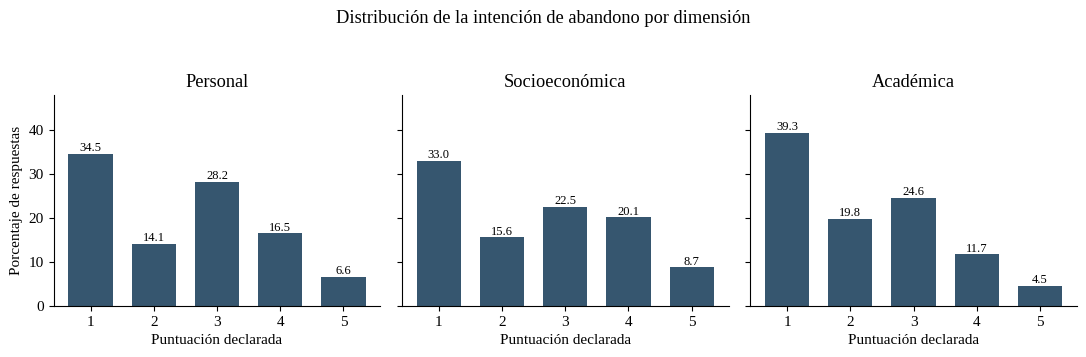

Las tres dimensiones conservan respuestas en las cinco categorías. En la escala recodificada, la puntuación 1 es la más frecuente en cada una. Los valores 4–5 se resumen sin convertirlos en una tasa de deserción.


In [16]:
freq_rows=[]
for col in processed:
    for category,n in processed[col].value_counts(dropna=False).items():
        freq_rows.append({'variable':col,'categoria':category,'n':int(n),'denominador':len(processed),
                          'porcentaje':float(n/len(processed)*100)})
save_table(pd.DataFrame(freq_rows),'frecuencias_variables')
target_rows=[]
for col in TARGETS:
    counts=clean[col].value_counts().reindex(range(1,6),fill_value=0)
    for value,n in counts.items():
        target_rows.append({'dimension':TARGET_LABELS[col],'puntuacion':value,'n':int(n),
                            'denominador':int(clean[col].notna().sum()),'porcentaje':float(n/clean[col].notna().sum()*100)})
target_distribution=pd.DataFrame(target_rows)
save_table(target_distribution,'distribucion_intencion')
ordinal_summary=clean[ORDINAL].astype(float).describe(percentiles=[.25,.5,.75]).T.reset_index(names='variable')
save_table(ordinal_summary,'resumen_ordinal')
high=[]
for col in TARGETS:
    n=int(clean[col].ge(4).sum());total=int(clean[col].notna().sum())
    high.append({'dimension':TARGET_LABELS[col],'n_puntuaciones_4_5':n,'denominador':total,'porcentaje':n/total*100})
high=pd.DataFrame(high)
save_table(high,'resumen_puntuaciones_4_5')
display(high.round(2))
fig,axes=plt.subplots(1,3,figsize=(11,3.4),sharey=True)
for ax,col in zip(axes,TARGETS):
    t=target_distribution[target_distribution.dimension.eq(TARGET_LABELS[col])]
    bars=ax.bar(t.puntuacion,t.porcentaje,color='#36566f',width=.7)
    ax.set_title(TARGET_LABELS[col]);ax.set_xlabel('Puntuación declarada');ax.set_xticks(range(1,6));ax.set_ylim(0,48)
    for bar,pct in zip(bars,t.porcentaje):ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+.6,f'{pct:.1f}',ha='center',fontsize=9)
axes[0].set_ylabel('Porcentaje de respuestas')
fig.suptitle('Distribución de la intención de abandono por dimensión',y=1.04)
fig.tight_layout();save_figure(fig,'01_distribucion_intencion')
print('Las tres dimensiones conservan respuestas en las cinco categorías. En la escala recodificada, la puntuación 1 es la más frecuente en cada una. Los valores 4–5 se resumen sin convertirlos en una tasa de deserción.')


## 5 EDA multivariado y sensibilidad a la codificación
Spearman es la referencia principal para las escalas ordinales. Pearson se calcula sobre esas mismas
puntuaciones como sensibilidad a la hipótesis de intervalos iguales, sin asignar números a categorías nominales.
No se usan valores p de esta exploración como confirmación de hipótesis; el protocolo fija las pruebas futuras.
La figura incluye predictores y resultados para explorar asociaciones, no para definir una matriz de entrenamiento.


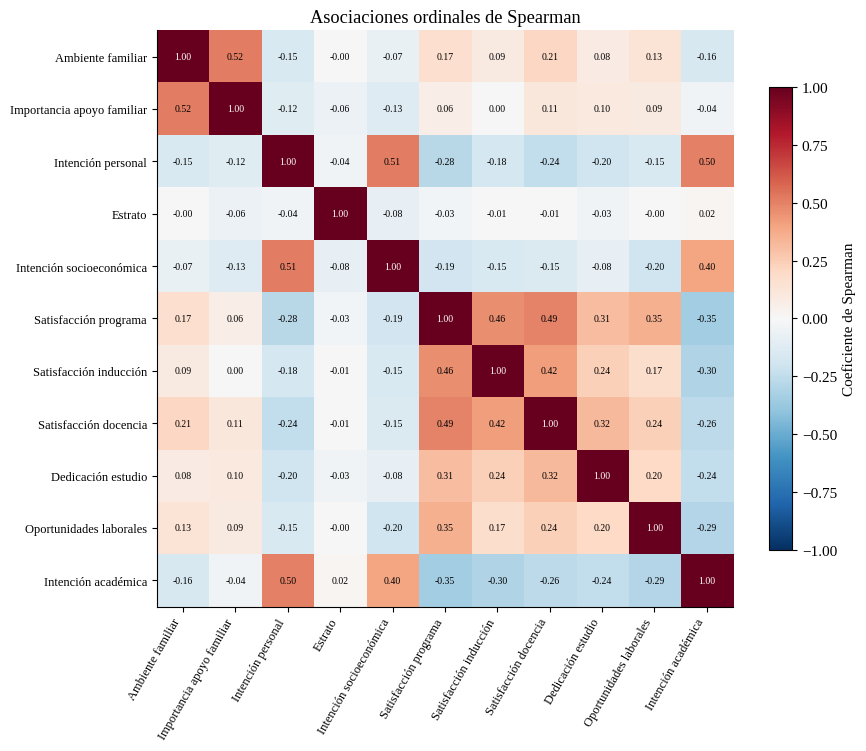

Asociaciones exploratorias de mayor magnitud por dimensión:


,dimension,predictor,n,rho_spearman,r_pearson_sensibilidad,diferencia_absoluta
19,Académica,satisfaccion_programa,333,-0.3488,-0.3310,0.0178
3,Personal,satisfaccion_programa,333,-0.2791,-0.2893,0.0102
15,Socioeconómica,oportunidades_laborales,333,-0.1973,-0.1955,0.0018


Las tres variables de intención usan 6 - x, siguiendo la aclaración específica de los autores. La satisfacción mantiene su dirección original. El cambio de signo frente a la versión anterior resulta de esta recodificación documentada, no de una selección por conveniencia.


In [17]:
numeric = clean[ORDINAL].astype(float)
spearman = numeric.corr(method='spearman')
pearson = numeric.corr(method='pearson')
save_table(spearman.reset_index(names='variable'),'correlaciones_spearman')
save_table(pearson.reset_index(names='variable'),'correlaciones_pearson_sensibilidad')
associations=[]
for target in TARGETS:
    for pred in PREDICTORS:
        rho=float(spearman.loc[pred,target]);r=float(pearson.loc[pred,target])
        associations.append({'dimension':TARGET_LABELS[target],'predictor':pred,'n':len(numeric),
                             'rho_spearman':rho,'r_pearson_sensibilidad':r,'diferencia_absoluta':abs(rho-r)})
associations=pd.DataFrame(associations)
save_table(associations,'asociaciones_exploratorias')
labels=['Ambiente familiar','Importancia apoyo familiar','Intención personal','Estrato','Intención socioeconómica',
        'Satisfacción programa','Satisfacción inducción','Satisfacción docencia','Dedicación estudio',
        'Oportunidades laborales','Intención académica']
fig,ax=plt.subplots(figsize=(9,8))
im=ax.imshow(spearman,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(labels)),labels,rotation=60,ha='right',fontsize=9)
ax.set_yticks(range(len(labels)),labels,fontsize=9)
for i in range(len(labels)):
    for j in range(len(labels)):
        v=spearman.iloc[i,j];ax.text(j,i,f'{v:.2f}',ha='center',va='center',fontsize=7,color='white' if abs(v)>.6 else 'black')
ax.set_title('Asociaciones ordinales de Spearman')
fig.colorbar(im,ax=ax,shrink=.7,label='Coeficiente de Spearman')
fig.tight_layout();save_figure(fig,'02_correlaciones_spearman')
print('Asociaciones exploratorias de mayor magnitud por dimensión:')
strongest=associations.loc[associations.groupby('dimension').rho_spearman.apply(lambda x:x.abs().idxmax()).values]
display(strongest.round(4))
print('Las tres variables de intención usan 6 - x, siguiendo la aclaración específica de los autores. La satisfacción mantiene su dirección original. El cambio de signo frente a la versión anterior resulta de esta recodificación documentada, no de una selección por conveniencia.')


## 6 Multicolinealidad
VIF se calcula mediante regresiones auxiliares con intercepto: VIF_j = 1/(1−R²_j).
Se usan solo las ocho variables ordinales explicativas, excluyendo los tres resultados y los pesos.
Se compara el VIF de puntuaciones con el de rangos medios como sensibilidad. Es un diagnóstico
de redundancia de esta matriz, no una selección definitiva de variables ni evidencia de causalidad.


In [18]:
def vif_table(frame, method):
    X=frame.to_numpy(dtype=float)
    if np.linalg.matrix_rank(np.column_stack([np.ones(len(X)),X])) != X.shape[1]+1:
        raise ValueError('Matriz de predictores no tiene rango completo.')
    out=[]
    for j,col in enumerate(frame):
        y=X[:,j];Z=np.column_stack([np.ones(len(X)),np.delete(X,j,axis=1)])
        beta=np.linalg.lstsq(Z,y,rcond=None)[0]
        sst=np.sum((y-y.mean())**2);sse=np.sum((y-Z@beta)**2)
        r2=1-sse/sst
        out.append({'variable':col,'representacion':method,'n':len(X),'r2_auxiliar':float(r2),'vif':float(1/(1-r2))})
    return pd.DataFrame(out)
vifs=pd.concat([vif_table(numeric[PREDICTORS],'Puntuaciones originales'),
                vif_table(numeric[PREDICTORS].rank(),'Rangos medios')],ignore_index=True)
save_table(vifs,'vif_predictores')
display(vifs.round(3))


,variable,representacion,n,r2_auxiliar,vif
0,apoyo_ambiente_familiar,Puntuaciones originales,333,0.300,1.429
1,importancia_apoyo_familiar,Puntuaciones originales,333,0.268,1.367
2,estrato,Puntuaciones originales,333,0.014,1.014
3,satisfaccion_programa,Puntuaciones originales,333,0.367,1.579
4,satisfaccion_induccion,Puntuaciones originales,333,0.270,1.370
5,satisfaccion_docencia,Puntuaciones originales,333,0.333,1.499
6,dedicacion_estudio,Puntuaciones originales,333,0.134,1.155
7,oportunidades_laborales,Puntuaciones originales,333,0.148,1.174
8,apoyo_ambiente_familiar,Rangos medios,333,0.298,1.424
9,importancia_apoyo_familiar,Rangos medios,333,0.277,1.383


## 7 Estabilidad descriptiva por subgrupos
Se presentan distribuciones por programa, sin asumir representatividad poblacional. Los tamaños
de cada grupo aparecen como denominadores. Se comparan las correlaciones de cada predictor con
cada resultado dentro de los programas; con tamaños pequeños su variabilidad puede ser amplia.
No se utilizan cruces de discapacidad, municipio o colegio.


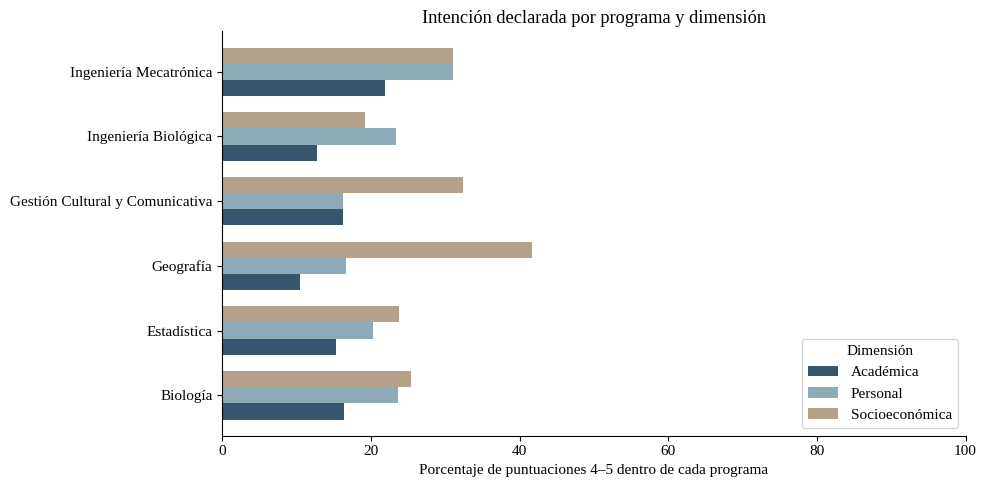

La figura muestra proporciones dentro de cada programa, no el tamaño de su matrícula. La comparación descriptiva requiere consultar los denominadores de intencion_por_programa.csv. No permite concluir que un programa tenga mayor deserción.


In [19]:
subgroups=[];group_corr=[]
for program,idx in clean.groupby('programa').groups.items():
    for target in TARGETS:
        x=clean.loc[idx,target].astype(float)
        subgroups.append({'programa':program,'dimension':TARGET_LABELS[target],'n':len(idx),
                          'mediana':float(x.median()),'n_4_5':int(x.ge(4).sum()),'porcentaje_4_5':float(x.ge(4).mean()*100)})
        for pred in PREDICTORS:
            a=clean.loc[idx,pred].astype(float)
            rho=float(stats.spearmanr(a,x).statistic) if a.nunique()>1 and x.nunique()>1 else np.nan
            group_corr.append({'programa':program,'dimension':TARGET_LABELS[target],'predictor':pred,'n':len(idx),'rho':rho})
subgroups=pd.DataFrame(subgroups);group_corr=pd.DataFrame(group_corr)
save_table(subgroups,'intencion_por_programa')
save_table(group_corr,'spearman_por_programa')
stability=[]
for _,row in strongest.iterrows():
    g=group_corr[(group_corr.dimension==row.dimension)&(group_corr.predictor==row.predictor)].dropna(subset=['rho'])
    stability.append({'dimension':row.dimension,'predictor':row.predictor,'rho_global':row.rho_spearman,
                      'programas_evaluados':len(g),'programas_mismo_signo':int((np.sign(g.rho)==np.sign(row.rho_spearman)).sum()),
                      'rho_minimo':float(g.rho.min()),'rho_maximo':float(g.rho.max()),
                      'interpretacion':'Coincidencia de signo descriptiva; no prueba de estabilidad estadística'})
save_table(pd.DataFrame(stability),'estabilidad_subgrupos')
plot_data=subgroups.pivot(index='programa',columns='dimension',values='porcentaje_4_5')
fig,ax=plt.subplots(figsize=(10,5))
plot_data.plot.barh(ax=ax,color=['#36566f','#8cabb6','#b4a18a'],width=.75)
ax.set_xlabel('Porcentaje de puntuaciones 4–5 dentro de cada programa')
ax.set_ylabel('');ax.set_xlim(0,100);ax.set_title('Intención declarada por programa y dimensión')
ax.legend(title='Dimensión',loc='lower right');fig.tight_layout()
save_figure(fig,'03_intencion_por_programa')
print('La figura muestra proporciones dentro de cada programa, no el tamaño de su matrícula. La comparación descriptiva requiere consultar los denominadores de intencion_por_programa.csv. No permite concluir que un programa tenga mayor deserción.')


## 8 Sensibilidad del campo de ponderaciones
Se comparan dos tratamientos: A) usar únicamente ternas válidas que suman 100; B) reescalar ternas
positivas y dentro de rango para que sumen 100. Los vectores de suma cero no pueden reescalarse.
Esta comparación no altera la base ni las variables de intención. Se contrasta el resultado agregado
para mostrar cuánto depende de la decisión de preparación. Los nombres de los tres pesos se asignan
según el orden personal/socioeconómico/académico descrito por la pregunta de origen.


In [20]:
positive=valid_range & weight_sum.gt(0)
strict=weights.loc[valid_sum]
normalized=weights.loc[positive].div(weight_sum.loc[positive],axis=0)*100
comparison=[]
for method,frame in [('A Solo suma 100',strict),('B Reescalar ternas positivas',normalized)]:
    for col in frame:
        comparison.append({'tratamiento':method,'factor':col,'n':len(frame),
                           'media_puntos':float(frame[col].mean()),'mediana_puntos':float(frame[col].median())})
save_table(pd.DataFrame(comparison),'sensibilidad_ponderaciones')
print('Casos estrictos:',len(strict),'Casos reescalables:',len(normalized),'Suma cero:',int(zero_sum.sum()))


Casos estrictos: 288 Casos reescalables: 313 Suma cero: 20


## 9 Protocolo de evaluación para la ruta descriptiva
Las pruebas siguientes están previstas para el ACA 3 y no se presentan aquí como confirmación.
Los indicadores de puntuaciones 4–5 son resúmenes de respuesta, no cortes validados de riesgo.
La respuesta ordinal completa es la referencia; las agrupaciones serán análisis de sensibilidad.
No corresponde una partición entrenamiento/prueba al no entrenarse un predictor.


In [21]:
protocol=pd.DataFrame([
 ['Distribución ordinal por dimensión','n de respuestas en categoría / n válidas × 100','Cinco categorías dentro de cada dimensión',
  'Chi-cuadrado solo si frecuencias esperadas permiten; alternativa por permutación si no','V de Cramér e intervalo bootstrap'],
 ['Puntuaciones 4–5','n con puntuación 4 o 5 / n válidas × 100','Proporciones dentro de programas y grupos; sin meta externa',
  'Contraste secundario; no sustituye las categorías completas','Diferencias en puntos porcentuales con intervalos'],
 ['Posición de la respuesta ordinal','Mediana y Q3 − Q1 de cada dimensión','Distribución global y grupos predefinidos',
  'Mann–Whitney para dos grupos; Kruskal–Wallis para más de dos','Correlación biserial por rangos o epsilon cuadrado'],
 ['Asociación ordinal','rho de Spearman entre predictor y dimensión','Ausencia de asociación monotónica (rho = 0)',
  'Permutación bilateral con 9999 permutaciones, semilla fija','Intervalo bootstrap pareado, 2000 remuestras'],
 ['Comparaciones múltiples','p ajustado por Holm','Familias predefinidas por tipo de contraste y dimensión',
  'Alfa 0,05; sin elegir pruebas por el resultado obtenido','Reportar tamaño del efecto e incertidumbre junto al valor p'],
 ['Reproducibilidad y sensibilidad','Tablas regeneradas y diferencias entre tratamientos','Mismos bytes, versiones y semilla; respuesta ordinal sin agrupar',
  'No corresponde división de entrenamiento/prueba ni línea base predictiva','Cumplimiento: trazabilidad y limitaciones explícitas, sin exigir resultados significativos']
],columns=['indicador','formula_o_definicion','referencia','prueba_prevista','reporte'])
save_table(protocol,'protocolo_descriptivo')
decisions=[
 ['D01','Fuente','Encuesta real colombiana con licencia CC BY 4.0','Simulación o datos de práctica','Cumple la fuente real exigida','ficha_dataset.csv'],
 ['D02','Resultado','Mantener tres respuestas ordinales, recodificadas 6 - x y con original conservado','Inventar deserción efectiva o una etiqueta única','No existe seguimiento de matrícula','distribucion_intencion.csv'],
 ['D03','Privacidad','Excluir marca temporal, municipio, colegio y discapacidad; agrupar detalle','Publicar original','Minimizar información no necesaria; no se garantiza anonimato formal','diccionario_original.csv'],
 ['D04','Faltantes','No imputar: no hay vacíos observados','Imputar automáticamente','Evitar tratamientos sin necesidad','etl_antes_despues.csv'],
 ['D05','Atípicos','Conservar valores válidos de escalas acotadas','Eliminar por IQR','Los extremos de una escala pueden ser respuestas válidas','revision_atipicos.csv'],
 ['D06','Ponderaciones','Comparar suma 100 y reescalado de ternas positivas','Corregir todo o eliminar participantes','La inconsistencia afecta un campo, no el registro completo','sensibilidad_ponderaciones.csv'],
 ['D07','Correlación','Spearman principal y Pearson como sensibilidad','Codificar nominales con enteros arbitrarios','Respetar la naturaleza ordinal','asociaciones_exploratorias.csv'],
 ['D08','VIF','Regresiones auxiliares solo entre ocho predictores','Incluir resultados o la suma de pesos','Evitar dependencias triviales y circularidad','vif_predictores.csv'],
 ['D09','Temporalidad','No analizar tendencias ni estacionalidad','Usar fecha de encuesta como serie de abandono','La fecha de respuesta no es seguimiento académico','ficha_dataset.csv'],
 ['D10','Validación','EDA ahora; pruebas confirmatorias previstas para ACA 3','Seleccionar hipótesis a partir de valores p','Separar exploración de confirmación','protocolo_descriptivo.csv'],
 ['D11','Subgrupos','Examinar patrones por programa con sus denominadores','Generalizar a toda la sede','Muestra voluntaria, sin pesos poblacionales','estabilidad_subgrupos.csv'],
 ['D12','IA','Declarar apoyo en programación, organización y revisión','Omitir apoyo o atribuirle validación autónoma','Responsabilidad de revisión y comprensión del autor','DECLARACION_IA.md'],
 ['D13','Interpretación de escalas','Registrar contradicción entre README general y publicación específica posterior','Ignorar contradicción documental','La dirección no se deduce de la correlación','auditoria_recodificacion_escalas.csv'],
 ['D14','Corrección documentada','Aplicar 6 - x solo a las tres preguntas de intención; conservar originales','Mantener lectura genérica de que alto = mayor intención','Artículo de los mismos autores, Cogent Education (2026), sección Variables, precisa dirección inversa; no se recuperó formulario original','auditoria_recodificacion_escalas.csv']
]
bitacora=pd.DataFrame(decisions,columns=['id','tema','decision','alternativas','justificacion','evidencia'])
bitacora.insert(1,'fecha_registro','2026-10-24')
bitacora.insert(2,'contexto','Registro al consolidar el cuaderno; antecedentes discutidos en la sesión')
save_table(bitacora,'bitacora_decisiones')
experiments=pd.DataFrame([{'id':'ACA1_EDA','objetivo':'Caracterización y exploración multivariada',
                          'metodo':'Descriptivo; Spearman; sensibilidad Pearson; VIF; subgrupos',
                          'semilla':SEED,'n':len(processed),'hiperparametros':'No aplica','modelo':'No entrenado',
                          'metricas_predictivas':'No aplica','fuente_sha256':source_sha256}])
experiments.to_csv(ROOT/'results/experiments.csv',index=False,encoding='utf-8-sig')
print('Protocolo, bitácora y registro de ejecución guardados.')


Protocolo, bitácora y registro de ejecución guardados.


## 10 Hallazgos para el documento y cierre del primer objetivo
Los textos siguientes se calculan desde las tablas. Son interpretaciones exploratorias y orientaciones
para estudiar necesidades, no recomendaciones individuales ni demostraciones de eficacia.


In [22]:
academic = high[high.dimension.eq('Académica')].iloc[0]
qbad = int((~valid_sum).sum())
f1=f"En la dimensión académica, {int(academic.n_puntuaciones_4_5)} de {int(academic.denominador)} participantes ({academic.porcentaje:.1f} %) eligieron puntuaciones 4–5. Este resumen no es una tasa de deserción. Sugiere explorar las experiencias académicas con las respuestas completas."
f2=f"Se identificaron {qbad} respuestas ({qbad/len(raw)*100:.1f} %) con ponderaciones que no suman 100. La decisión es comparar tratamientos para ese campo y conservar las otras respuestas de esos participantes."
best=strongest.loc[strongest.rho_spearman.abs().idxmax()]
f3=f"La asociación exploratoria de mayor magnitud entre los predictores y las tres dimensiones corresponde a {best.predictor} y la dimensión {best.dimension.lower()} (rho = {best.rho_spearman:.3f}). La intención se recodificó con 6 - x por la aclaración específica de los autores. Mayor satisfacción se asocia con menor puntuación analítica de intención, sin demostrar causalidad."
findings=pd.DataFrame({'hallazgo':[f1,f2,f3]})
save_table(findings,'hallazgos_y_decisiones')
for f in findings.hallazgo: print(f+'\n')
summary={'n':len(raw),'columnas_originales':raw.shape[1],'columnas_preparadas':processed.shape[1],
         'faltantes_originales':missing_raw,'duplicados_originales':duplicate_full,
         'pesos_suma100':int(valid_sum.sum()),'pesos_suma_cero':int(zero_sum.sum()),
         'vif_max_puntuaciones':float(vifs[vifs.representacion.eq('Puntuaciones originales')].vif.max()),
         'vif_max_rangos':float(vifs[vifs.representacion.eq('Rangos medios')].vif.max()),
         'tablas_generadas':len(list(TABLES.glob('*.csv'))),'sha256_original':source_sha256,
         'regla_intencion':'6 - x; originales preservados; aclaración específica Cogent Education 2026',
         'doi_aclaracion':'10.1080/2331186X.2026.2722463'}
(ROOT/'results/resumen_ejecucion.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('Primer objetivo: preparación y caracterización exploratoria documentadas.')
print('Pendientes externos: confirmar fecha de descarga, revisar con el autor, cargar Colab/GitHub y crear release v0.1.')


En la dimensión académica, 54 de 333 participantes (16.2 %) eligieron puntuaciones 4–5. Este resumen no es una tasa de deserción. Sugiere explorar las experiencias académicas con las respuestas completas.

Se identificaron 45 respuestas (13.5 %) con ponderaciones que no suman 100. La decisión es comparar tratamientos para ese campo y conservar las otras respuestas de esos participantes.

La asociación exploratoria de mayor magnitud entre los predictores y las tres dimensiones corresponde a satisfaccion_programa y la dimensión académica (rho = -0.349). La intención se recodificó con 6 - x por la aclaración específica de los autores. Mayor satisfacción se asocia con menor puntuación analítica de intención, sin demostrar causalidad.

Primer objetivo: preparación y caracterización exploratoria documentadas.
Pendientes externos: confirmar fecha de descarga, revisar con el autor, cargar Colab/GitHub y crear release v0.1.


In [25]:
from zipfile import ZipFile, ZIP_DEFLATED
from importlib.metadata import version
from google.colab import files

carpeta = ROOT
paquetes = ["numpy", "pandas", "scipy", "matplotlib", "openpyxl"]

(carpeta / "requirements.txt").write_text(
    "\n".join(f"{p}=={version(p)}" for p in paquetes) + "\n",
    encoding="utf-8"
)

archivo = carpeta / "resultados_colab_ACA1.zip"

with ZipFile(archivo, "w", ZIP_DEFLATED) as zip_salida:
    for ruta in ["data/processed", "results"]:
        for elemento in (carpeta / ruta).rglob("*"):
            if elemento.is_file():
                zip_salida.write(
                    elemento,
                    elemento.relative_to(carpeta)
                )

    zip_salida.write(
        carpeta / "requirements.txt",
        "requirements.txt"
    )

files.download(str(archivo))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>